 ### Step 1: Import Required Libraries



###Step 2 Load the CIFAR-10 dataset


###Step 3: Extract Visual Features Using ResNet-50

###Step 4: Extract Textual Features Using CLIP

###Step 5: Feature Standardization and reduce dimension

###Step 6: Clustering Functions

###Results:

 ### Visualizing clusters

Using device: cuda
Extracting features using ResNet-50...

ResNet feature extraction complete.

Extracting features using CLIP...

CLIP feature extraction complete.
Optimal number of components to explain 95% of variance: 263


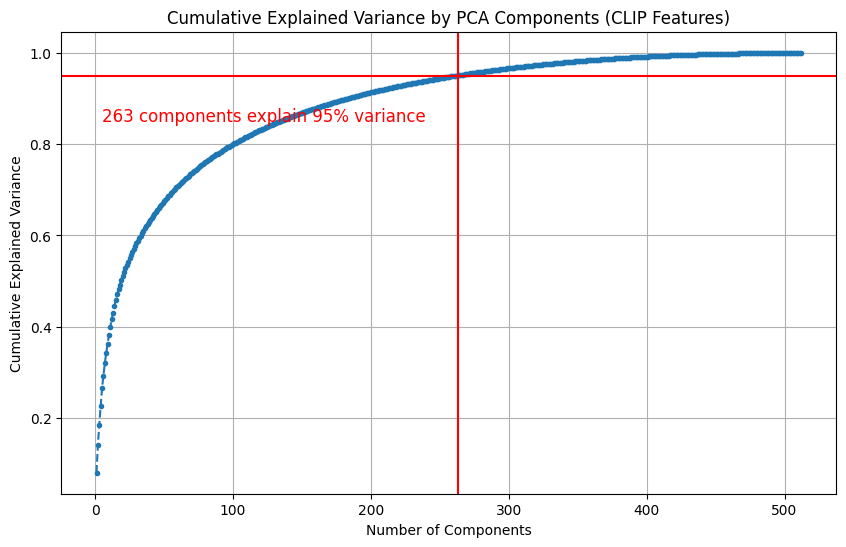


Applying PCA with n_components=263...
Final feature shapes after PCA: ResNet=(60000, 263), CLIP=(60000, 263), Combined=(60000, 263)

--- Clustering on ResNet-50 Features ---
K-Means Kappa: 0.3025
GMM Kappa:     0.1249

--- Clustering on CLIP Features ---
K-Means Kappa: 0.8432
GMM Kappa:     0.6081

--- Clustering on Combined Features ---
K-Means Kappa: 0.5843
GMM Kappa:     0.2706

Running t-SNE for visualization: 't-SNE of CLIP Features (Colored by True Label)'...


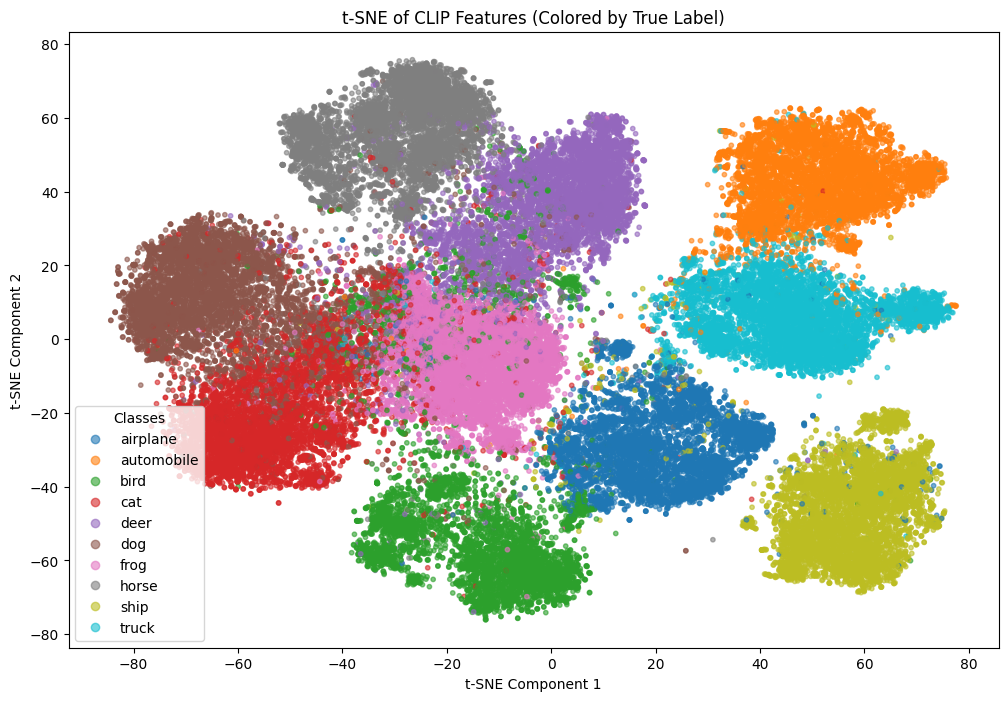

In [ ]:
### Step 1: Install Required Libraries

!pip install openTSNE -q

### Step 2: Import Libraries

import numpy as np
import torch
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
import matplotlib.pyplot as plt
from collections import Counter

# Scikit-learn imports for clustering and evaluation
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import cohen_kappa_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# PyTorch and Torchvision imports
from torch.utils.data import DataLoader, ConcatDataset
from torchvision.datasets import CIFAR10

# Hugging Face Transformers for CLIP
from transformers import CLIPProcessor, CLIPModel

# openTSNE for visualization
from openTSNE import TSNE


### Step 3: Setup Device and Load Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def load_cifar10():
    transform_pipeline = transforms.Compose([
        transforms.ToTensor()
    ])

    train_data = CIFAR10(root="./data", train=True, download=True, transform=transform_pipeline)
    test_data = CIFAR10(root="./data", train=False, download=True, transform=transform_pipeline)

    dataset = ConcatDataset([train_data, test_data])
    data_loader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=2)
    return data_loader, train_data.classes

data_loader, class_labels = load_cifar10()


### Step 4: Feature Extraction

def extract_resnet_features(model, loader):
    model.eval()
    feature_list, labels_list = [], []
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    with torch.no_grad():
        for i, (batch_tensors, batch_labels) in enumerate(loader):
            print(f"Processing ResNet batch {i+1}/{len(loader)}", end='\r')
            normalized_tensors = normalize(batch_tensors).to(device)
            features = model(normalized_tensors).view(normalized_tensors.size(0), -1)
            feature_list.append(features.cpu().numpy())
            labels_list.extend(batch_labels.numpy())

    print("\nResNet feature extraction complete.")
    return np.vstack(feature_list), np.array(labels_list)

def extract_clip_image_features(loader):
    model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
    processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    model.eval()
    feature_list = []

    with torch.no_grad():
        for i, (batch_tensors, _) in enumerate(loader):
            print(f"Processing CLIP batch {i+1}/{len(loader)}", end='\r')
            inputs = processor(images=batch_tensors, return_tensors="pt", padding=True, do_rescale=False)
            inputs = {key: val.to(device) for key, val in inputs.items()}
            image_embeddings = model.get_image_features(**inputs)
            feature_list.append(image_embeddings.cpu().numpy())

    print("\nCLIP feature extraction complete.")
    return np.vstack(feature_list)

# --- Extract Features ---
print("Extracting features using ResNet-50...")
resnet50 = models.resnet50(weights='IMAGENET1K_V1').to(device)
resnet50 = nn.Sequential(*list(resnet50.children())[:-1])
resnet_features, true_labels = extract_resnet_features(resnet50, data_loader)

print("\nExtracting features using CLIP...")
clip_features = extract_clip_image_features(data_loader)

# --- Standardize Features ---
scaler_resnet = StandardScaler()
scaled_resnet_features = scaler_resnet.fit_transform(resnet_features)

scaler_clip = StandardScaler()
scaled_clip_features = scaler_clip.fit_transform(clip_features)


### Step 5: Find Optimal PCA Components

# We analyze our strongest feature set (CLIP) to find the best number of components.
# We then apply this optimal number to ALL feature sets for a fair comparison.
pca_analysis = PCA(random_state=42)
pca_analysis.fit(scaled_clip_features)
cumulative_variance = np.cumsum(pca_analysis.explained_variance_ratio_)

# Find the number of components to explain 95% of the variance
n_components_optimal = np.argmax(cumulative_variance >= 0.95) + 1
print(f"Optimal number of components to explain 95% of variance: {n_components_optimal}")

# Plot the explained variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='.', linestyle='--')
plt.title('Cumulative Explained Variance by PCA Components (CLIP Features)')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.axhline(y=0.95, color='r', linestyle='-')
plt.axvline(x=n_components_optimal, color='r', linestyle='-')
plt.text(5, 0.85, f'{n_components_optimal} components explain 95% variance', color='red', fontsize=12)
plt.show()


### Step 6: Feature Preprocessing with Optimal PCA

print(f"\nApplying PCA with n_components={n_components_optimal}...")
pca = PCA(n_components=n_components_optimal, random_state=42)

reduced_resnet_features = pca.fit_transform(scaled_resnet_features)
reduced_clip_features = pca.fit_transform(scaled_clip_features)

combined_features = np.hstack((scaled_resnet_features, scaled_clip_features))
reduced_combined_features = pca.fit_transform(combined_features)

print(f"Final feature shapes after PCA: ResNet={reduced_resnet_features.shape}, CLIP={reduced_clip_features.shape}, Combined={reduced_combined_features.shape}")


### Step 7: Clustering and Evaluation Functions

def assign_cluster_labels(cluster_predictions, actual_labels):
    cluster_ids = np.unique(cluster_predictions)
    label_map = {}
    for cluster in cluster_ids:
        indices = np.where(cluster_predictions == cluster)[0]
        if len(indices) == 0:
            continue
        most_common_label = Counter(actual_labels[indices]).most_common(1)[0][0]
        label_map[cluster] = most_common_label
    return np.array([label_map.get(c, -1) for c in cluster_predictions])

def perform_clustering(features, labels, method_name=""):
    print(f"\n--- Clustering on {method_name} Features ---")

    # K-Means
    kmeans = KMeans(n_clusters=10, random_state=42, n_init=10).fit(features)
    kmeans_preds = assign_cluster_labels(kmeans.labels_, labels)
    print(f"K-Means Kappa: {cohen_kappa_score(labels, kmeans_preds):.4f}")

    # Gaussian Mixture Model
    gmm = GaussianMixture(n_components=10, covariance_type='diag', random_state=42).fit(features)
    gmm_cluster_labels = gmm.predict(features)
    gmm_preds = assign_cluster_labels(gmm_cluster_labels, labels)
    print(f"GMM Kappa:     {cohen_kappa_score(labels, gmm_preds):.4f}")


### Step 8: Run Experiments

# --- Experiment 1: ResNet-50 Features ---
perform_clustering(reduced_resnet_features, true_labels, "ResNet-50")

# --- Experiment 2: CLIP Features ---
perform_clustering(reduced_clip_features, true_labels, "CLIP")

# --- Experiment 3: Combined Features ---
perform_clustering(reduced_combined_features, true_labels, "Combined")


### Step 9: Visualize Clusters

def visualize_clusters(features, labels, title):
    print(f"\nRunning t-SNE for visualization: '{title}'...")
    tsne = TSNE(n_components=2, perplexity=50, random_state=42, n_jobs=-1)
    reduced_tsne = tsne.fit(features)

    plt.figure(figsize=(12, 8))
    scatter = plt.scatter(reduced_tsne[:, 0], reduced_tsne[:, 1], c=labels, cmap='tab10', alpha=0.6, s=10)

    handles, _ = scatter.legend_elements()
    plt.legend(handles, class_labels, title="Classes")
    plt.title(title)
    plt.xlabel("t-SNE Component 1")
    plt.ylabel("t-SNE Component 2")
    plt.show()

# Visualize the best performing feature set (CLIP)
visualize_clusters(reduced_clip_features, true_labels, "t-SNE of CLIP Features (Colored by True Label)")